In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from src.tree_propagation.environment import EnvironmentState
from src.tree_propagation.simulation import simulate_seed_shadow
from src.tree_propagation.tree_config import load_tree_configs
from src.tree_propagation.visualization import (
    draw_compass_labels,
    draw_mean_radius,
    draw_parent,
    draw_wind_rose_boundaries,
    plot_distance_histogram,
    plot_seed_shadow,
    plot_simulated_seed_shadow_and_distance_histogram,
)
from src.tree_propagation.wind_config import DEFAULT_WIND_ROSE


In [2]:
logging.basicConfig(level=logging.INFO)

In [3]:
RANDOM_SEED = 10
rng = np.random.default_rng(RANDOM_SEED)

In [4]:
species_config = load_tree_configs("./data/trees_vienna.csv")
species_config

{'Ahorn': TreeConfig(species_name='Ahorn', dispersal_type=<DispersalType.WIND: 'wind'>, wind_spreading_factor=0.9, mean_dispersal_distance=None, fecundity=2.0, maturity_age=20, years_per_height_class=12, maximal_height_class=5, mean_life_span=120, shade_tolerance=0.8),
 'Akazie': TreeConfig(species_name='Akazie', dispersal_type=<DispersalType.GRAVITY: 'gravity'>, wind_spreading_factor=None, mean_dispersal_distance=10.0, fecundity=3.0, maturity_age=6, years_per_height_class=7, maximal_height_class=5, mean_life_span=60, shade_tolerance=0.18),
 'Buche': TreeConfig(species_name='Buche', dispersal_type=<DispersalType.ANIMAL: 'animal'>, wind_spreading_factor=None, mean_dispersal_distance=30.0, fecundity=1.2, maturity_age=30, years_per_height_class=18, maximal_height_class=6, mean_life_span=150, shade_tolerance=0.89),
 'Esche': TreeConfig(species_name='Esche', dispersal_type=<DispersalType.WIND: 'wind'>, wind_spreading_factor=0.7, mean_dispersal_distance=None, fecundity=2.4, maturity_age=20, 

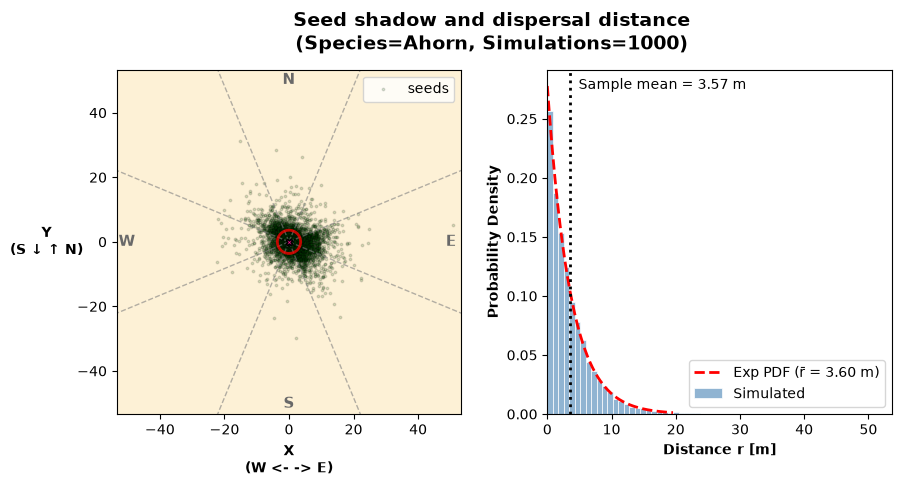

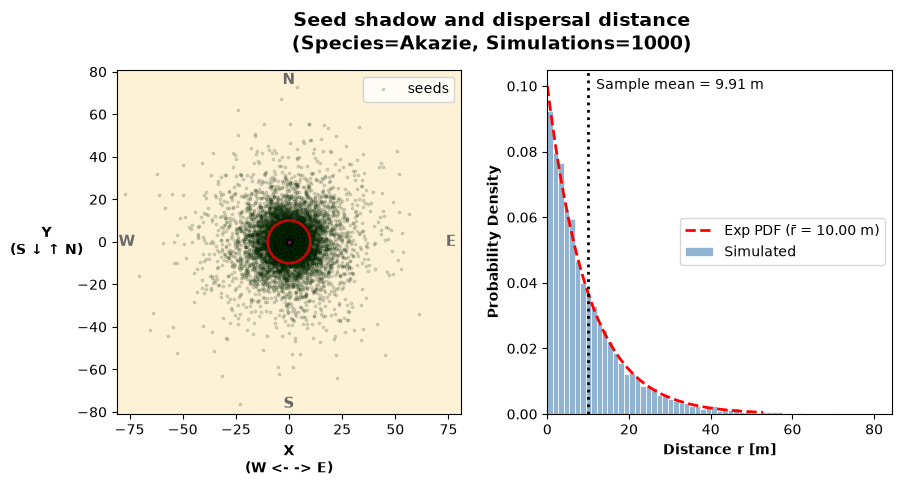

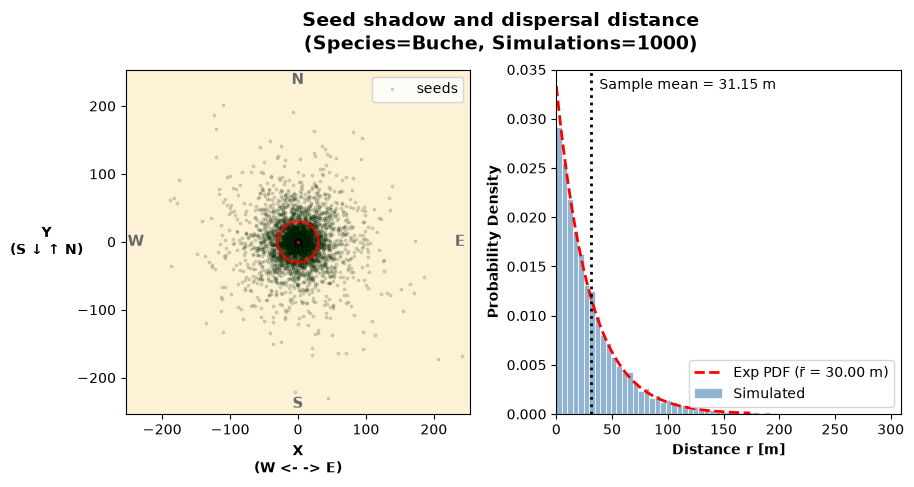

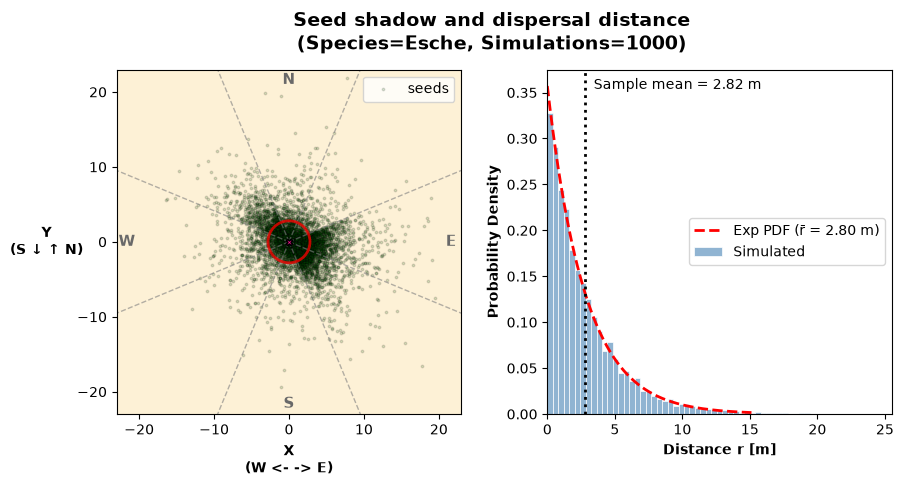

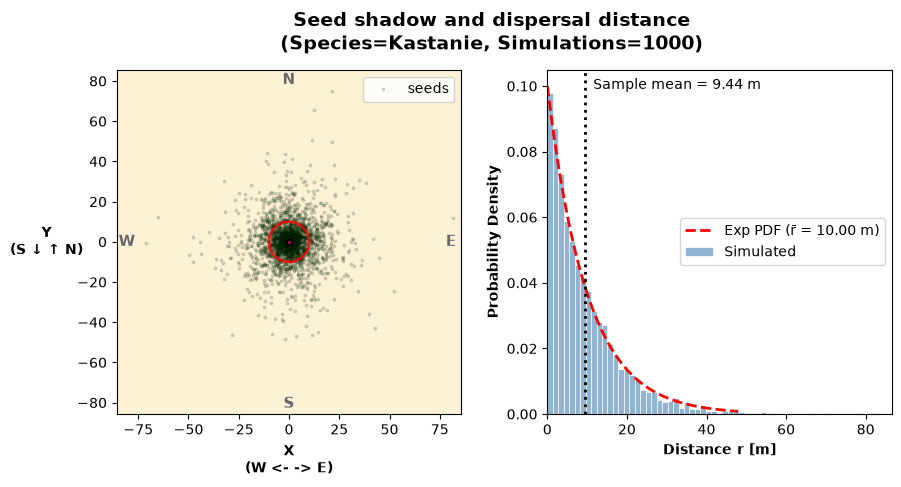

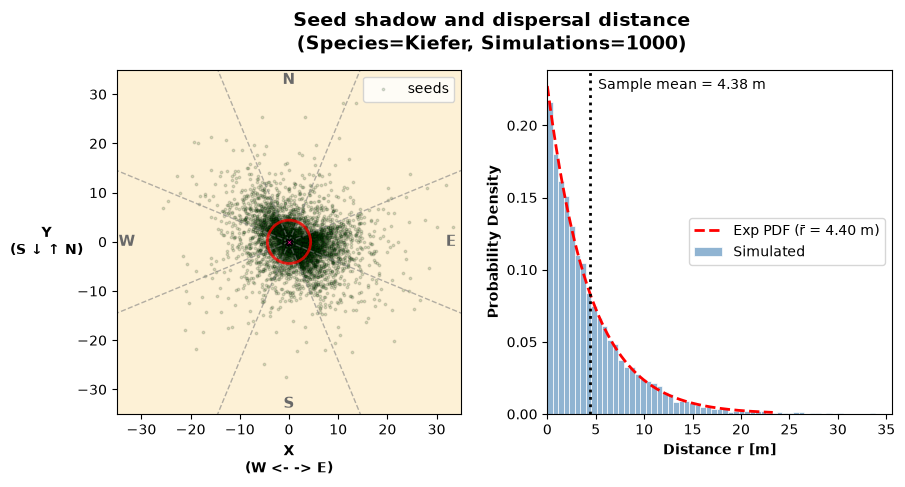

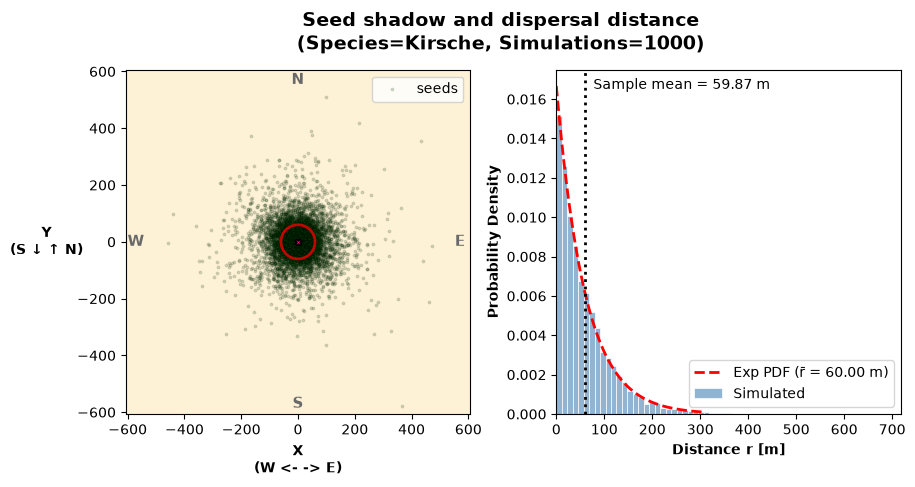

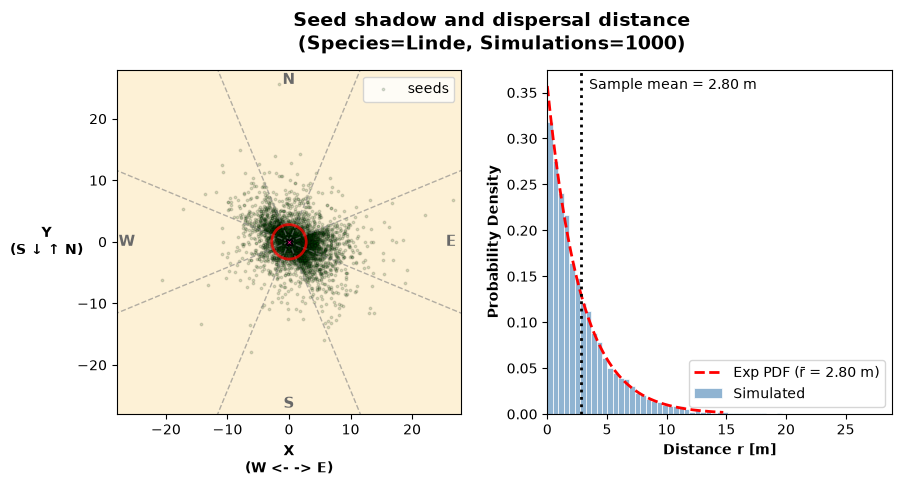

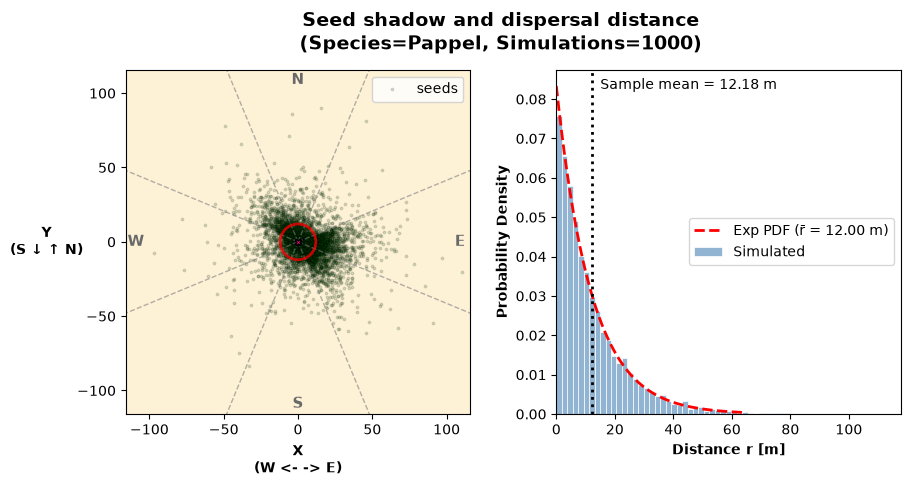

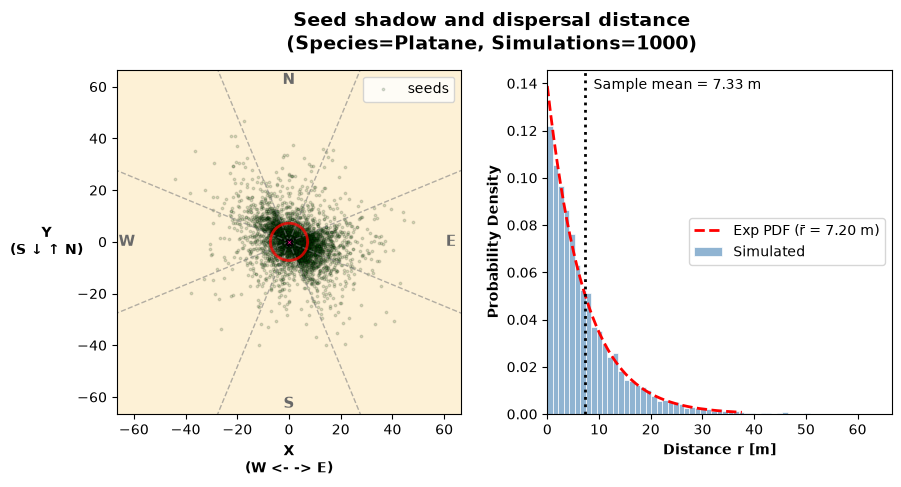

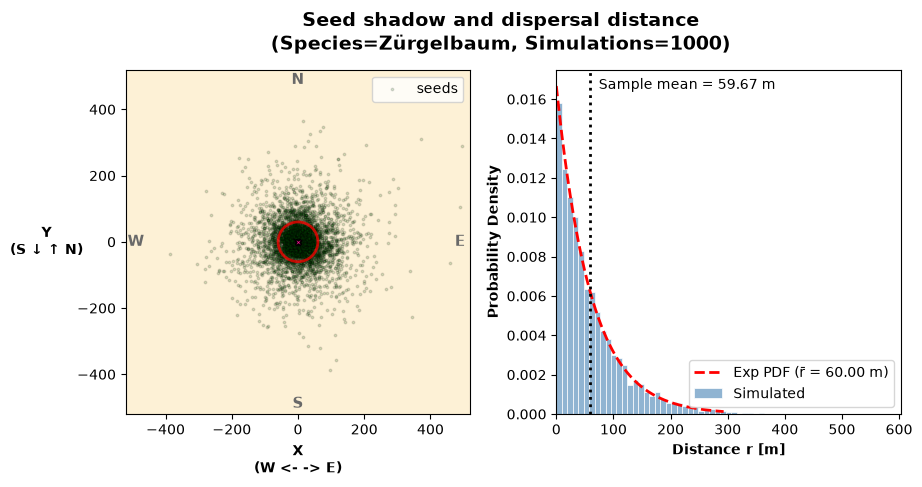

In [5]:
for tree_species_config in species_config.values():
    sim_result = simulate_seed_shadow(
        config=tree_species_config, 
        environment_state=EnvironmentState(wind_rose=DEFAULT_WIND_ROSE, wind_strength=1),
        height_class=4,
        num_instances=1_000,
        rng=rng
    )
    fig = plot_simulated_seed_shadow_and_distance_histogram(result=sim_result, size=(10, 5))